<a href="https://colab.research.google.com/github/potopinc/colab/blob/main/ML_11.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Импорт библиотек

In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import accuracy_score
from sklearn.model_selection import cross_val_score

In [ ]:
accuracy = доля правильных ответов

accuracy = <число верных раундов классификации> / <общее число раундов классификация>

# Описание набора данных

- **Hours_Studied** — количество часов, потраченных на учёбу в неделю.
- **Attendance** — процент посещаемости занятий.
- **Parental_Involvement** — уровень вовлечённости родителей в образование студента.
- **Access_to_Resources** — доступность образовательных ресурсов.
- **Extracurricular_Activities** — участие во внеклассных мероприятиях.
- **Sleep_Hours** — среднее количество часов сна.
- **Previous_Scores** — результаты предыдущих экзаменов.
- **Motivation_Level** — уровень мотивации студента.
- **Internet_Access** — наличие доступа к Интернету.
- **Tutoring_Sessions** — количество дополнительных занятий в месяц.
- **Family_Income** — уровень семейного дохода.
- **Teacher_Quality** — уровень преподавателей.
- **School_Type** — тип посещаемой школы.
- **Peer_Influence** — влияние сверстников на успеваемость.
- **Physical_Activity** — среднее количество часов физической активности в неделю.
- **Learning_Disabilities** — наличие трудностей в обучении.
- **Parental_Education_Level** — уровень образования родителей.
- **Distance_from_Home** — расстояние от дома до школы.
- **Gender** — пол студента.
- **Exam_Score** — оценка за экзамен.

# Загрузка и обработка данных

In [ ]:
df = pd.read_csv('students_perfomance.csv')
df

,Hours_Studied,Attendance,Parental_Involvement,Access_to_Resources,Extracurricular_Activities,Sleep_Hours,Previous_Scores,Motivation_Level,Internet_Access,Tutoring_Sessions,Family_Income,Teacher_Quality,School_Type,Peer_Influence,Physical_Activity,Learning_Disabilities,Parental_Education_Level,Distance_from_Home,Gender,Exam_Score
0,23,84,Low,High,No,7,73,Low,Yes,0,Low,Medium,Public,Positive,3,No,High School,Near,Male,medium
1,19,64,Low,Medium,No,8,59,Low,Yes,2,Medium,Medium,Public,Negative,4,No,College,Moderate,Female,low
2,24,98,Medium,Medium,Yes,7,91,Medium,Yes,2,Medium,Medium,Public,Neutral,4,No,Postgraduate,Near,Male,very_high
3,29,89,Low,Medium,Yes,8,98,Medium,Yes,1,Medium,Medium,Public,Negative,4,No,High School,Moderate,Male,high
4,19,92,Medium,Medium,Yes,6,65,Medium,Yes,3,Medium,High,Public,Neutral,4,No,College,Near,Female,medium_high
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
6602,25,69,High,Medium,No,7,76,Medium,Yes,1,High,Medium,Public,Positive,2,No,High School,Near,Female,medium
6603,23,76,High,Medium,No,8,81,Medium,Yes,3,Low,High,Public,Positive,2,No,High School,Near,Female,medium_high
6604,20,90,Medium,Low,Yes,6,65,Low,Yes,3,Low,Medium,Public,Negative,2,No,Postgraduate,Near,Female,medium
6605,10,86,High,High,Yes,6,91,High,Yes,2,Low,Medium,Private,Positive,3,No,High School,Far,Female,medium


In [ ]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 6607 entries, 0 to 6606
Data columns (total 20 columns):
 #   Column                      Non-Null Count  Dtype 
---  ------                      --------------  ----- 
 0   Hours_Studied               6607 non-null   int64 
 1   Attendance                  6607 non-null   int64 
 2   Parental_Involvement        6607 non-null   object
 3   Access_to_Resources         6607 non-null   object
 4   Extracurricular_Activities  6607 non-null   object
 5   Sleep_Hours                 6607 non-null   int64 
 6   Previous_Scores             6607 non-null   int64 
 7   Motivation_Level            6607 non-null   object
 8   Internet_Access             6607 non-null   object
 9   Tutoring_Sessions           6607 non-null   int64 
 10  Family_Income               6607 non-null   object
 11  Teacher_Quality             6529 non-null   object
 12  School_Type                 6607 non-null   object
 13  Peer_Influence              6607 non-null   obje

In [ ]:
# !!! O = object !!!

text_f = [f for f in df.columns if df[f].dtype == 'O']
numeric_f = [f for f in df.columns if df[f].dtype != 'O']

In [ ]:
text_f

['Parental_Involvement',
 'Access_to_Resources',
 'Extracurricular_Activities',
 'Motivation_Level',
 'Internet_Access',
 'Family_Income',
 'Teacher_Quality',
 'School_Type',
 'Peer_Influence',
 'Learning_Disabilities',
 'Parental_Education_Level',
 'Distance_from_Home',
 'Gender',
 'Exam_Score']

In [ ]:
numeric_f

['Hours_Studied',
 'Attendance',
 'Sleep_Hours',
 'Previous_Scores',
 'Tutoring_Sessions',
 'Physical_Activity']

In [ ]:
len(text_f) + len(numeric_f) == len(df.columns)

True

In [ ]:
small_df = df[numeric_f]
small_df

,Hours_Studied,Attendance,Sleep_Hours,Previous_Scores,Tutoring_Sessions,Physical_Activity
0,23,84,7,73,0,3
1,19,64,8,59,2,4
2,24,98,7,91,2,4
3,29,89,8,98,1,4
4,19,92,6,65,3,4
...,...,...,...,...,...,...
6602,25,69,7,76,1,2
6603,23,76,8,81,3,2
6604,20,90,6,65,3,2
6605,10,86,6,91,2,3


In [ ]:
small_df.isna().sum()

,0
Hours_Studied,0
Attendance,0
Sleep_Hours,0
Previous_Scores,0
Tutoring_Sessions,0
Physical_Activity,0


<Axes: ylabel='count'>

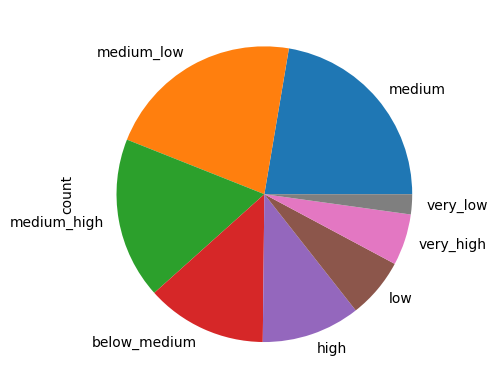

In [ ]:
df['Exam_Score'].value_counts().plot(kind='pie')

# Формируем X, y

In [ ]:
X = small_df
y = df['Exam_Score']

In [ ]:
X.shape

(6607, 6)

In [ ]:
y.shape

(6607,)

# Базовая модель

In [ ]:
print(cross_val_score(KNeighborsClassifier(), X, y, cv=5).mean())

0.3920087587796802


#### **Задание 1**

Построй график зависимости `accuracy` (по результатам `cross_val_score`) от количества соседей в диапазоне от 1 до 111.

Выведи максимальное значение accuracy и оптимальное количество соседей.

In [ ]:
cross_val_score(KNeighborsClassifier(n_neighbors=3), X, y, cv=5)

array([0.37670197, 0.37216339, 0.4004542 , 0.35730507, 0.38380015])

In [ ]:
acc = np.array([cross_val_score(KNeighborsClassifier(n_neighbors=n), X, y, cv=5).mean() for n in range(1, 111)])
acc

array([0.36219203, 0.35825802, 0.37808496, 0.38383634, 0.39200876,
       0.4027551 , 0.40487493, 0.41319726, 0.41516501, 0.4192503 ,
       0.42379255, 0.42439907, 0.42091937, 0.42379358, 0.42515607,
       0.42379243, 0.43030139, 0.42621564, 0.42893787, 0.42621324,
       0.42893776, 0.42545784, 0.4298457 , 0.42878647, 0.42757527,
       0.43014885, 0.43045222, 0.42984719, 0.4302999 , 0.42924159,
       0.42969442, 0.43075388, 0.42878533, 0.42484995, 0.42742272,
       0.43211465, 0.43060122, 0.42954153, 0.43377994, 0.4360506 ,
       0.42984456, 0.42878498, 0.43166113, 0.43302294, 0.43423368,
       0.43922887, 0.43620315, 0.43438669, 0.433327  , 0.43468971,
       0.43408434, 0.43469006, 0.43726341, 0.43423654, 0.43287394,
       0.43181494, 0.43302477, 0.43348034, 0.43363071, 0.43423689,
       0.43423723, 0.43151248, 0.43529612, 0.43393397, 0.43363083,
       0.43454106, 0.43045291, 0.43166377, 0.43030185, 0.42924285,
       0.4319684 , 0.43196726, 0.43166594, 0.43227063, 0.43121

In [ ]:
len(acc)

110

Text(0, 0.5, 'accuracy')

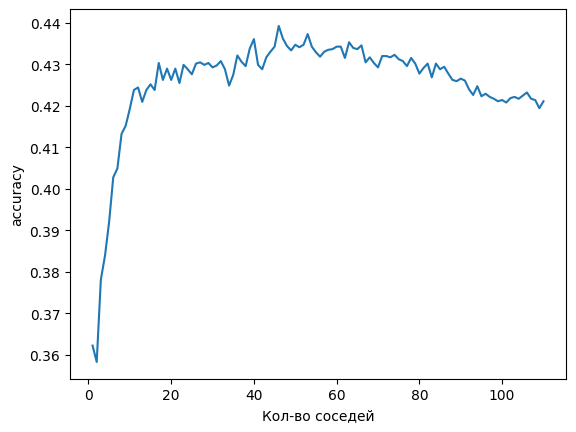

In [ ]:
plt.plot(range(1, 111), acc)
plt.xlabel('Кол-во соседей')
plt.ylabel('accuracy')

In [ ]:
acc.max(), acc.argmax()

(np.float64(0.4392288654929505), np.int64(45))

In [ ]:
acc[acc.argmax()]

np.float64(0.4392288654929505)

#### **Задание 2**

Какие текстовые признаки можно использовать при обучении модели?

Обработай текстовые признаки.

Проверь nan.

Повторно выполни задание 1 для измененного набора данных.

In [ ]:
for f in text_f:
  print(f, df[f].value_counts().index.to_list())

Parental_Involvement ['Medium', 'High', 'Low']
Access_to_Resources ['Medium', 'High', 'Low']
Extracurricular_Activities ['Yes', 'No']
Motivation_Level ['Medium', 'Low', 'High']
Internet_Access ['Yes', 'No']
Family_Income ['Low', 'Medium', 'High']
Teacher_Quality ['Medium', 'High', 'Low']
School_Type ['Public', 'Private']
Peer_Influence ['Positive', 'Neutral', 'Negative']
Learning_Disabilities ['No', 'Yes']
Parental_Education_Level ['High School', 'College', 'Postgraduate']
Distance_from_Home ['Near', 'Moderate', 'Far']
Gender ['Male', 'Female']
Exam_Score ['medium', 'medium_low', 'medium_high', 'below_medium', 'high', 'low', 'very_high', 'very_low']


In [ ]:
df[text_f].mode().iloc[0]

,0
Parental_Involvement,Medium
Access_to_Resources,Medium
Extracurricular_Activities,Yes
Motivation_Level,Medium
Internet_Access,Yes
Family_Income,Low
Teacher_Quality,Medium
School_Type,Public
Peer_Influence,Positive
Learning_Disabilities,No


In [ ]:
df[text_f].isna().sum()

,0
Parental_Involvement,0
Access_to_Resources,0
Extracurricular_Activities,0
Motivation_Level,0
Internet_Access,0
Family_Income,0
Teacher_Quality,78
School_Type,0
Peer_Influence,0
Learning_Disabilities,0


In [ ]:
df[text_f] = df[text_f].fillna(df[text_f].mode().iloc[0])

In [ ]:
df[text_f].isna().sum()

,0
Parental_Involvement,0
Access_to_Resources,0
Extracurricular_Activities,0
Motivation_Level,0
Internet_Access,0
Family_Income,0
Teacher_Quality,0
School_Type,0
Peer_Influence,0
Learning_Disabilities,0


In [ ]:
# Создаем единый словарь для перевода
mapping = {
    'Low': 1, 'Medium': 2, 'High': 3,
    'No': 0, 'Yes': 1,
    'Female': 0, 'Male': 1,
    'Public': 0, 'Private': 1,
}

In [ ]:
df = df.replace(mapping)

/tmp/ipykernel_2771/3750686369.py:1: FutureWarning: Downcasting behavior in `replace` is deprecated and will be removed in a future version. To retain the old behavior, explicitly call `result.infer_objects(copy=False)`. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
  df = df.replace(mapping)


In [ ]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 6607 entries, 0 to 6606
Data columns (total 20 columns):
 #   Column                      Non-Null Count  Dtype 
---  ------                      --------------  ----- 
 0   Hours_Studied               6607 non-null   int64 
 1   Attendance                  6607 non-null   int64 
 2   Parental_Involvement        6607 non-null   int64 
 3   Access_to_Resources         6607 non-null   int64 
 4   Extracurricular_Activities  6607 non-null   int64 
 5   Sleep_Hours                 6607 non-null   int64 
 6   Previous_Scores             6607 non-null   int64 
 7   Motivation_Level            6607 non-null   int64 
 8   Internet_Access             6607 non-null   int64 
 9   Tutoring_Sessions           6607 non-null   int64 
 10  Family_Income               6607 non-null   int64 
 11  Teacher_Quality             6607 non-null   int64 
 12  School_Type                 6607 non-null   int64 
 13  Peer_Influence              6607 non-null   obje

In [ ]:
# Заменяем значения
df.head()

,Hours_Studied,Attendance,Parental_Involvement,Access_to_Resources,Extracurricular_Activities,Sleep_Hours,Previous_Scores,Motivation_Level,Internet_Access,Tutoring_Sessions,Family_Income,Teacher_Quality,School_Type,Peer_Influence,Physical_Activity,Learning_Disabilities,Parental_Education_Level,Distance_from_Home,Gender,Exam_Score
0,23,84,1,3,0,7,73,1,1,0,1,2,0,Positive,3,0,High School,Near,1,medium
1,19,64,1,2,0,8,59,1,1,2,2,2,0,Negative,4,0,College,Moderate,0,low
2,24,98,2,2,1,7,91,2,1,2,2,2,0,Neutral,4,0,Postgraduate,Near,1,very_high
3,29,89,1,2,1,8,98,2,1,1,2,2,0,Negative,4,0,High School,Moderate,1,high
4,19,92,2,2,1,6,65,2,1,3,2,3,0,Neutral,4,0,College,Near,0,medium_high


In [ ]:
X = df.select_dtypes(exclude=['object'])
y = df['Exam_Score']

In [ ]:
acc = np.array([cross_val_score(KNeighborsClassifier(n_neighbors=n), X, y, cv=5).mean() for n in range(10, 60)])
acc

array([0.43348206, 0.43272483, 0.44044339, 0.4384753 , 0.44135019,
       0.44316871, 0.44392457, 0.43847507, 0.44195774, 0.44271405,
       0.44785778, 0.44634503, 0.44755589, 0.44770695, 0.44770683,
       0.44588911, 0.44498117, 0.44452662, 0.4418021 , 0.44528191,
       0.44770397, 0.44422268, 0.44286041, 0.44134721, 0.43771543,
       0.44074195, 0.43937878, 0.44286019, 0.4433153 , 0.44210341,
       0.44346499, 0.44467653, 0.44634285, 0.44724988, 0.44528282,
       0.44876331, 0.44755257, 0.44740197, 0.44377031, 0.44467791,
       0.44301399, 0.44543674, 0.44452845, 0.44694972, 0.44800975,
       0.44437717, 0.44543731, 0.4451352 , 0.44452926, 0.4431678 ])

Text(0, 0.5, 'accuracy')

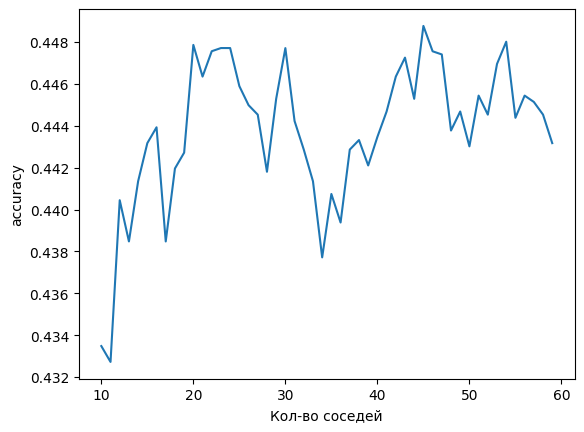

In [ ]:
plt.plot(range(10, 60), acc)
plt.xlabel('Кол-во соседей')
plt.ylabel('accuracy')

In [ ]:
acc.max(), acc.argmax()

(np.float64(0.44876331482247095), np.int64(35))

#### **Задание 3**

Учитывай расстояние до ближайших соседей.

In [ ]:
acc = np.array([cross_val_score(KNeighborsClassifier(n_neighbors=n, weights='distance'), X, y, cv=5).mean() for n in range(10, 60)])
acc.max(), acc.argmax()

(np.float64(0.45391035764635285), np.int64(19))

#### **Задание 4**

Используя любой scaler, отмасштабируй данные.

In [ ]:
from sklearn.preprocessing import StandardScaler

In [ ]:
X_scaled = StandardScaler().fit_transform(X)

In [ ]:
X_scaled

array([[ 0.50494151,  0.34837541, -1.56214574, ...,  0.03141133,
        -0.34286661,  0.85574648],
       [-0.16282241, -1.38373605, -1.56214574, ...,  1.00119947,
        -0.34286661, -1.16857039],
       [ 0.67188249,  1.56085343, -0.12426654, ...,  1.00119947,
        -0.34286661,  0.85574648],
       ...,
       [ 0.00411857,  0.86800885, -0.12426654, ..., -0.93837681,
        -0.34286661, -1.16857039],
       [-1.66529123,  0.52158655,  1.31361266, ...,  0.03141133,
        -0.34286661, -1.16857039],
       [-0.83058633, -1.12391933, -0.12426654, ...,  1.00119947,
        -0.34286661,  0.85574648]])

In [ ]:
acc = np.array([cross_val_score(KNeighborsClassifier(n_neighbors=n, weights='distance'), X_scaled, y, cv=5).mean() for n in range(10, 60)])
acc.max(), acc.argmax()

(np.float64(0.37808529961142073), np.int64(35))

Text(0, 0.5, 'accuracy')

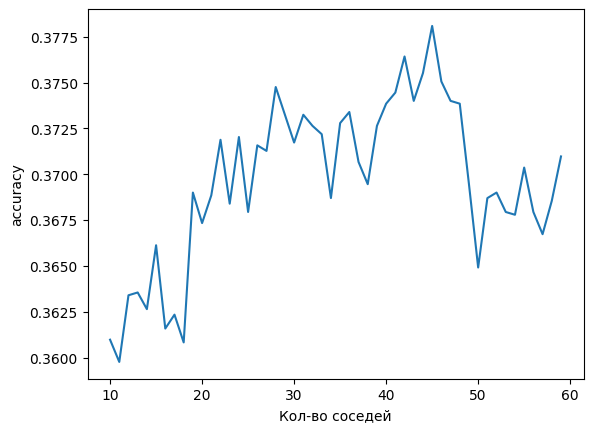

In [ ]:
plt.plot(range(10, 60), acc)
plt.xlabel('Кол-во соседей')
plt.ylabel('accuracy')

#### **Задание 5**

Измени способ подсчета расстояния. Например, используй манхэттенское расстояние.

In [ ]:
acc = np.array([cross_val_score(KNeighborsClassifier(n_neighbors=n, weights='distance', metric='manhattan'), X_scaled, y, cv=5).mean() for n in range(10, 60)])
acc.max(), acc.argmax()

(np.float64(0.3821712794941713), np.int64(36))

#### **Задание 6**

Попробуй получить значение `accuracy` больше. Для этого:

- найди оптимальную комбинацию параметров `KNeighborsClassifier`;
- попробуй другие способы масштабирования;
- если неоюходимо, измени обработку данных